<img src="https://github.com/hernancontigiani/ceia_memorias_especializacion/raw/master/Figures/logoFIUBA.jpg" width="500" align="center">

# **Visión por Computadora 3D**
# **Tarea 1, Clasificación de frutas con Depth Estimation y CNN 3D**

En este notebook partimos de fotos comunes (no de nubes de puntos).

El proceso que se realizará en este notebook es el siguiente:

1. descargamos fotos de frutas y verduras sobre fondo blanco (Fruits-360)
2. estimamos un mapa de profundidad para cada foto con Depth Anything V2
3. convertimos cada foto en una nube de puntos con el modelo de cámara pinhole
4. voxelizamos y entrenamos la misma CNN 3D de la clase, solo con la forma y con forma y color
5. comparamos con una CNN 2D que mira directamente la foto
6. probamos los clasificadores con imágenes propias

---
**Objetivo**

Clasificar frutas y verduras a partir de fotos comunes, convirtiéndolas en una representación 3D (nube de puntos y vóxeles), y comparar ese enfoque con una CNN 2D que mira la foto directamente.

**Descripción**

En este notebook se parte de fotos de Fruits-360 sobre fondo blanco. Para cada foto se estima un mapa de profundidad con Depth Anything V2. Con el modelo de cámara pinhole, ese mapa se convierte en una nube de puntos, que luego se voxeliza. Con los vóxeles se entrenan dos CNN 3D, una que usa solo la forma y otra que usa forma y color, y sus resultados se comparan con los de una CNN 2D. Al final se prueban los modelos con fotos propias.



---
**Instrucciones**

* Complete el código faltante en cada celda marcada con #TU CODIGO AQUI. El notebook debe ejecutarse completo, de principio a fin, sin errores.
* Después de la matriz de confusión, interprete los resultados.
* Realice los ejercicios propuestos al final del notebook. En cada uno, anote el resultado obtenido y responda la pregunta en uno o dos párrafos.
* Entregue el notebook descargado en este link https://forms.gle/t1jjETaro6mfrdCY9 con las celdas ejecutadas, de modo que se vean las salidas, los gráficos y sus respuestas

---
**1.- Importamos lo necesario**

In [1]:
import os
import glob
import time
import subprocess
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from PIL import Image
from scipy.ndimage import binary_fill_holes
from transformers import AutoModelForDepthEstimation

usamos la GPU si está disponible y fijamos la semilla para que los resultados se puedan repetir

In [2]:
DISP = "cuda" if torch.cuda.is_available() else "cpu"
torch.manual_seed(0)
print("dispositivo:", DISP)

dispositivo: cuda


**2.- Dataset: Fruits-360**

Fruits-360 tiene fotos de 100 × 100 píxeles de frutas y verduras sobre fondo blanco, tomadas mientras la fruta gira frente a la cámara. Cada carpeta del repositorio es una sola fruta fotografiada desde muchos ángulos: "Pineapple 1" es una piña, "Pineapple Mini 1" es otra

si entrenamos y evaluamos con fotos de la misma fruta, la red puede memorizar esa fruta en particular (su color exacto, sus manchas) y sacar casi 100 % sin aprender qué es una piña. Para evitarlo:
* entrenamos con varias frutas (variedades) por clase
* evaluamos con una variedad que la red nunca vio

así la accuracy de test mide lo que pasaría con una fruta nueva, como la de una foto propia

para cada clase: las variedades de entrenamiento y la variedad de test

In [3]:
VARIEDADES = {
    "banana": (["Banana 1", "Banana 3", "Banana 4", "Banana Lady Finger 1"], "Banana 2"),
    "manzana": (["Apple Red 1", "Apple Golden 1", "Apple Granny Smith 1", "Apple Braeburn 1", "Apple Pink Lady 1"], "Apple Red 2"),
    "pera": (["Pear 1", "Pear Abate 1", "Pear Forelle 1", "Pear Red 1", "Pear Williams 1"], "Pear 2"),
    "fresa": (["Strawberry 1", "Strawberry 3"], "Strawberry 2"),
    "piña": (["Pineapple 1"], "Pineapple Mini 1"),
    "pimiento": (["Pepper Red 1", "Pepper Red 4", "Pepper Green 1", "Pepper Yellow 1", "Pepper Orange 1"], "Pepper Red 3"),
    "champiñón": (["Mushroom champignon 1", "Mushroom champignon 2", "Mushroom champignon 3"], "Mushroom champignon 4"),
    "kiwi": (["Kiwi 1", "Kiwi 2"], "Kiwi 3"),
}
CLASES = list(VARIEDADES)

el repositorio completo pesa varios GB, así que lo clonamos sin archivos y después pedimos solo las carpetas que usamos

In [4]:
if not os.path.exists("frutas"):
    subprocess.run(["git", "clone", "-q", "--depth", "1", "--filter=blob:none", "--sparse",
                    "https://github.com/fruits-360/fruits-360-100x100", "frutas"], check=True)
rutas = [f"/Training/{c}" for tr, te in VARIEDADES.values() for c in tr + [te]]
subprocess.run(["git", "-C", "frutas", "sparse-checkout", "set", "--no-cone", *rutas], check=True)

CompletedProcess(args=['git', '-C', 'frutas', 'sparse-checkout', 'set', '--no-cone', '/Training/Banana 1', '/Training/Banana 3', '/Training/Banana 4', '/Training/Banana Lady Finger 1', '/Training/Banana 2', '/Training/Apple Red 1', '/Training/Apple Golden 1', '/Training/Apple Granny Smith 1', '/Training/Apple Braeburn 1', '/Training/Apple Pink Lady 1', '/Training/Apple Red 2', '/Training/Pear 1', '/Training/Pear Abate 1', '/Training/Pear Forelle 1', '/Training/Pear Red 1', '/Training/Pear Williams 1', '/Training/Pear 2', '/Training/Strawberry 1', '/Training/Strawberry 3', '/Training/Strawberry 2', '/Training/Pineapple 1', '/Training/Pineapple Mini 1', '/Training/Pepper Red 1', '/Training/Pepper Red 4', '/Training/Pepper Green 1', '/Training/Pepper Yellow 1', '/Training/Pepper Orange 1', '/Training/Pepper Red 3', '/Training/Mushroom champignon 1', '/Training/Mushroom champignon 2', '/Training/Mushroom champignon 3', '/Training/Mushroom champignon 4', '/Training/Kiwi 1', '/Training/Kiwi 

esta función arma la lista de archivos y etiquetas:
* cuales = "train" toma las variedades de entrenamiento, cuales = "test" la variedad de test
* si una clase tiene más de maximo fotos, elige maximo al azar, así ninguna clase domina el entrenamiento

In [5]:
def listar(cuales, maximo):
    gen = np.random.default_rng(0)
    archivos, etiquetas = [], []
    for y, clase in enumerate(CLASES):
        tr, te = VARIEDADES[clase]
        carpetas = tr if cuales == "train" else [te]
        f = sorted(sum([glob.glob(f"frutas/Training/{c}/*.jpg") for c in carpetas], []))
        if len(f) > maximo:
            f = [str(x) for x in gen.choice(f, maximo, replace=False)]
        archivos += f
        etiquetas += [y] * len(f)
    return archivos, torch.tensor(etiquetas)

In [6]:
arch_tr, ytr = listar("train", 600)
arch_te, yte = listar("test", 250)
print("entrenamiento:", len(arch_tr), ", test:", len(arch_te))

entrenamiento: 4690 , test: 1974


vemos imagenes del dataset

arriba una foto de entrenamiento de cada clase, abajo una de la variedad de test

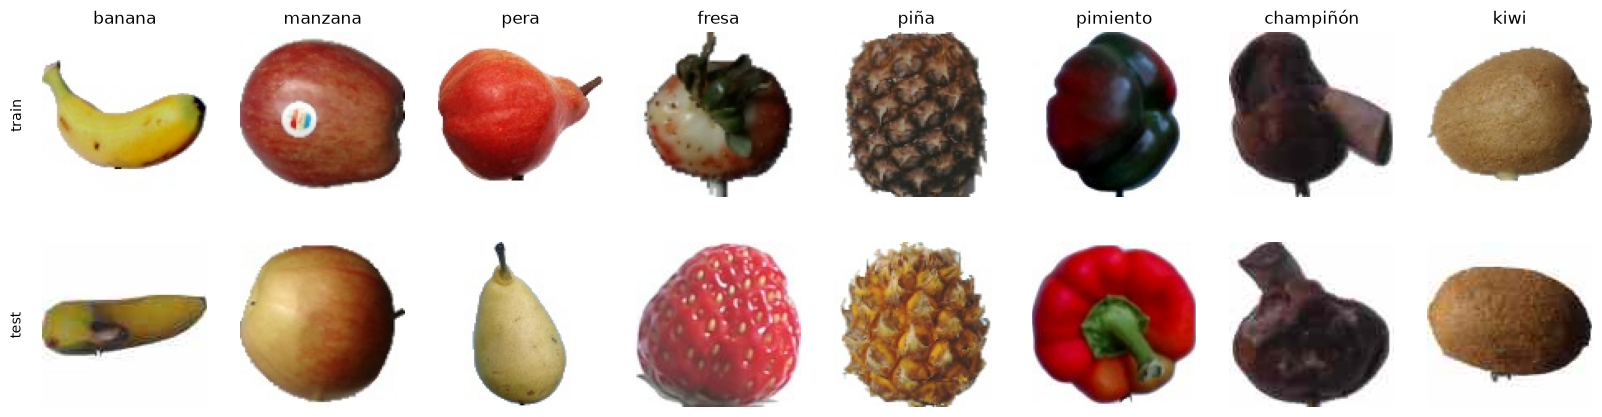

In [7]:
fig, ax = plt.subplots(2, len(CLASES), figsize=(20, 5))
for y in range(len(CLASES)):
    ax[0, y].imshow(Image.open(arch_tr[(ytr == y).nonzero()[0, 0]])); ax[0, y].set_title(CLASES[y])
    ax[1, y].imshow(Image.open(arch_te[(yte == y).nonzero()[0, 0]]))
    ax[0, y].axis("off"); ax[1, y].axis("off")
ax[0, 0].text(-20, 50, "train", rotation=90, va="center"); ax[1, 0].text(-20, 50, "test", rotation=90, va="center")
plt.show()

**3.- Mapa de profundidad con Depth Anything V2**

Depth Anything V2 estima la profundidad a partir de una sola imagen. Usamos la versión Small (25 M de parámetros): https://huggingface.co/depth-anything/Depth-Anything-V2-Small-hf

In [8]:
modelo_prof = AutoModelForDepthEstimation.from_pretrained("depth-anything/Depth-Anything-V2-Small-hf").to(DISP).eval()

W1109 01:25:27.684000 29392 Lib\site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


Loading weights:   0%|          | 0/287 [00:00<?, ?it/s]

esta función recibe un lote de imágenes ell con forma (B, 3, ALTO, ANCHO) y valores en [0, 1], y devuelve un mapa de profundidad por imagen:
* agranda las imágenes a 518 × 518, el tamaño con el que se entrenó el modelo (tiene que ser múltiplo de 14, el tamaño de los parches del ViT)
* normaliza con la media y el desvío de ImageNet
* predice y vuelve a achicar el mapa al tamaño original

ojo: el modelo devuelve profundidad **relativa e invertida**, valores altos = cerca y valores bajos = lejos, y sin unidades

In [9]:
MEDIA = torch.tensor([0.485, 0.456, 0.406], device=DISP)[:, None, None]
DESV = torch.tensor([0.229, 0.224, 0.225], device=DISP)[:, None, None]

def profundidad(ell):
    x = F.interpolate(ell, size=(518, 518), mode="bicubic", align_corners=False)
    x = (x - MEDIA) / DESV
    with torch.no_grad():
        d = modelo_prof(pixel_values=x).predicted_depth[:, None]   # (B, 1, 518, 518)
    return F.interpolate(d, size=ell.shape[-2:], mode="bilinear", align_corners=False)[:, 0]

esta función abre una lista de archivos y los convierte en un tensor (B, 3, ALTO, ANCHO) con valores en [0, 1]

In [10]:
def cargar(archivos):
    ell = np.stack([np.array(Image.open(f).convert("RGB")) for f in archivos])
    return torch.tensor(ell, device=DISP).permute(0, 3, 1, 2).float() / 255

el fondo es blanco, así que todo píxel con los tres canales por encima de 0.9 lo tomamos como fondo. binary_fill_holes rellena los huecos dentro del objeto, por ejemplo brillos blancos sobre la fruta

In [11]:
def mascara(ell):
    objeto = (ell.min(0).values < 0.9).cpu().numpy()
    return torch.tensor(binary_fill_holes(objeto), device=ell.device)

probamos con una foto de cada clase: imagen, mapa de profundidad (claro = cerca) y máscara del objeto

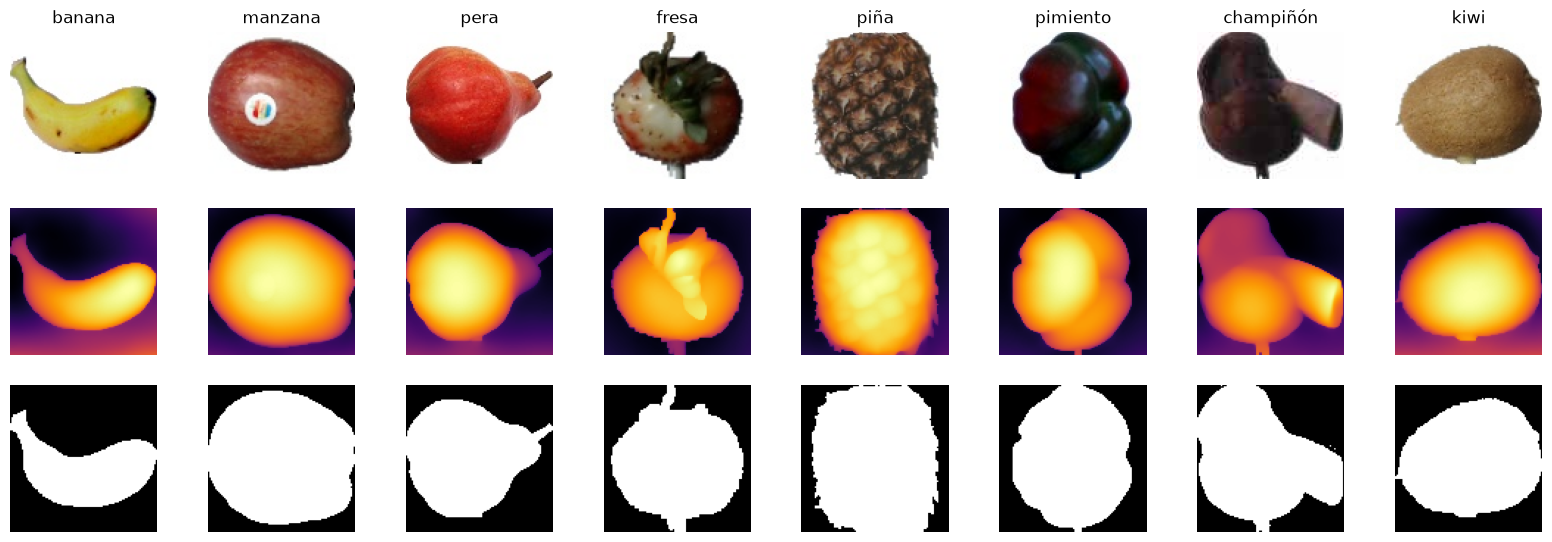

In [12]:
ejemplos = [arch_tr[(ytr == y).nonzero()[0, 0]] for y in range(len(CLASES))]
ell_ej = cargar(ejemplos)
d_ej = profundidad(ell_ej)

fig, ax = plt.subplots(3, len(CLASES), figsize=(20, 6.5))
for k in range(len(CLASES)):
    ax[0, k].imshow(ell_ej[k].permute(1, 2, 0).cpu()); ax[0, k].set_title(CLASES[k])
    ax[1, k].imshow(d_ej[k].cpu(), cmap="inferno")
    ax[2, k].imshow(mascara(ell_ej[k]).cpu(), cmap="gray")
    for a in ax[:, k]: a.axis("off")
plt.show()

 **4.- De profundidad a nube de puntos**

Usamos el modelo pinhole: un píxel (m, n) con profundidad z corresponde al punto 3D

$$
X = \frac{(n-c_x)\cdot z}{a}, \qquad
Y = \frac{(m-c_y)\cdot z}{b}, \qquad
Z = z
$$

donde a y b son las distancias focales en píxeles y (c_x, c_y) el centro óptico. Tomamos las focales de la cámara de NYU Depth (518.9 y 519.5 para imágenes de 640 de ancho) escaladas a nuestro ancho. Como nuestras fotos son cuadradas, ponemos el centro óptico en el centro de la imagen

In [13]:
ALTO, ANCHO = 100, 100
escala = ANCHO / 640
a, b = 518.9 * escala, 519.5 * escala
c_x, c_y = ANCHO / 2, ALTO / 2

Depth Anything no da metros, así que construimos una profundidad aproximada:
* normalizamos la profundidad del objeto a [0, 1] (1 = punto más cercano)
* ubicamos el objeto a Z0 = 1 m de la cámara
* le damos un relieve igual a la mitad de su ancho, como una fruta redonda vista de frente, de la que solo vemos la mitad delantera

la escala exacta no importa mucho porque después normalizamos cada nube, lo que importa es la proporción entre el relieve y el ancho

In [14]:
Z0 = 1.0

def a_metros(d, m):
    dn = (d - d[m].min()) / (d[m].max() - d[m].min() + 1e-6)   # 0 = lejos, 1 = cerca
    columnas = m.any(0).nonzero()
    ancho = (columnas.max() - columnas.min() + 1) * Z0 / a          # ancho del objeto en metros
    return Z0 + 0.5 * ancho * (1 - dn)

la función nube dibuja la nube con plotly, cada punto con el color de su píxel. Es la misma que vimos antes, pero recibe la máscara m para no dibujar el fondo

In [15]:
def nube(ell, z, m, paso=1):
    mm, nn_ = torch.meshgrid(torch.arange(ALTO, device=z.device), torch.arange(ANCHO, device=z.device), indexing="ij")
    X, Y = (nn_ - c_x) * z / a, (mm - c_y) * z / b
    sel = m[::paso, ::paso].reshape(-1)
    P = torch.stack([X, Y, z], -1)[::paso, ::paso].reshape(-1, 3)[sel].cpu().numpy()
    color = (ell.permute(1, 2, 0)[::paso, ::paso].reshape(-1, 3)[sel].cpu().numpy() * 255).astype(int)
    return go.Scatter3d(x=P[:, 0], y=P[:, 2], z=-P[:, 1], mode="markers",
                        marker=dict(size=1.5, color=[f"rgb({r},{g},{b_})" for r, g, b_ in color]))

el siguiente bloque deberia mostrar una fruta en nube de puntos

In [16]:
i = 2   # cambie el número para ver otra clase
m = mascara(ell_ej[i])
fig = go.Figure(nube(ell_ej[i], a_metros(d_ej[i], m), m))
fig.update_layout(scene=dict(aspectmode="data"), height=500, margin=dict(l=0, r=0, t=0, b=0))
fig.show()

para la red necesitamos nubes del mismo tamaño y en el rango [−1, 1], como las de ModelNet40. Esta función:
* calcula X, Y, Z de cada píxel del objeto, y guarda también su color
* elige 1024 puntos al azar (hay entre 2000 y 7000 píxeles de objeto por foto)
* centra la nube y la escala para que quepa en la esfera de radio 1

In [17]:
def a_nube(ell, d, N=1024):
    m = mascara(ell)
    z = a_metros(d, m)
    mm, nn_ = torch.meshgrid(torch.arange(ALTO, device=z.device), torch.arange(ANCHO, device=z.device), indexing="ij")
    # Aplica la formula mencionada en el punto 4
    X, Y = (nn_ - c_x) * z / a, (mm - c_y) * z / b
    P = torch.stack([X, Y, z], -1)[m]                  # (puntos del objeto, 3)
    color = ell.permute(1, 2, 0)[m]                    # (puntos del objeto, 3)
    sel = torch.randint(len(P), (N,), device=P.device)
    P, color = P[sel], color[sel]
    P = P - (P.max(0).values + P.min(0).values) / 2    # centra
    return P / P.norm(dim=1).max(), color              # escala a la esfera de radio 1

esta función procesa una lista de archivos por lotes: carga, estima profundidad y arma las nubes. Devuelve:
* X (B, 1024, 3) con las posiciones de los puntos
* C (B, 1024, 3) con sus colores
* I (B, 3, 64, 64) con las fotos achicadas, para la CNN 2D de la sección 7

In [18]:
def procesar(archivos, lote=32):
    X, C, I = [], [], []
    for k in range(0, len(archivos), lote):
        ell = cargar(archivos[k:k + lote])
        d = profundidad(ell)
        I.append(F.interpolate(ell, size=(64, 64), mode="area"))
        for e, dd in zip(ell, d):
            p, c = a_nube(e, dd)
            X.append(p); C.append(c)
    return torch.stack(X), torch.stack(C), torch.cat(I)

procesamos todo el dataset, en la T4 tarda unos minutos

In [19]:
t0 = time.time()
Xtr, Ctr, Itr = procesar(arch_tr, lote=16)
Xte, Cte, Ite = procesar(arch_te, lote=16)
ytr, yte = ytr.to(DISP), yte.to(DISP)
print("entrenamiento:", tuple(Xtr.shape), "| test:", tuple(Xte.shape), f"| {time.time() - t0:.0f} s")

entrenamiento: (4690, 1024, 3) | test: (1974, 1024, 3) | 148 s


**5.- Voxelizar con color**

Es la misma función que vimos en la clase, con un cambio: si le pasamos los colores C, la grilla tiene 4 canales en lugar de 1
* canal 0: ocupado o no
* canales 1, 2 y 3: el color R, G, B del punto que cayó en ese cubo (si caen varios, queda uno de ellos)

recordar la formula para voxelizar:

$$
i = \operatorname{clamp}\left(
\left\lfloor \frac{P+1}{2}\cdot R \right\rfloor,
0,
R-1
\right)
$$

In [20]:
def voxelizar(P, R, C=None):
    i = ((P + 1) / 2 * R).long().clamp(0, R - 1)
    V = torch.zeros(len(P), 1 if C is None else 4, R, R, R, device=P.device)
    b = torch.arange(len(P), device=P.device)[:, None]
    V[b, 0, i[..., 0], i[..., 1], i[..., 2]] = 1
    if C is not None:
        for c in range(3):
            V[b, c + 1, i[..., 0], i[..., 1], i[..., 2]] = C[..., c]
    return V

vemos tres objetos voxelizados a 32³, pintando cada cubo con su color

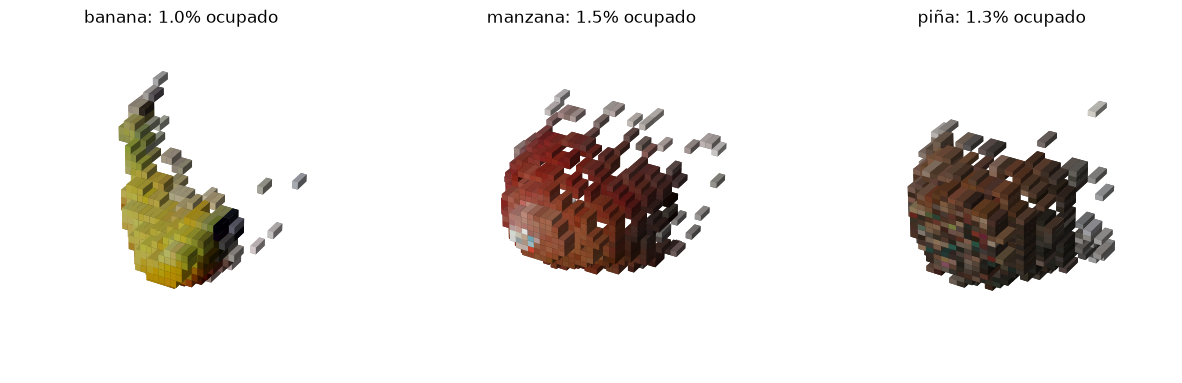

In [21]:
fig = plt.figure(figsize=(15, 5))
for k, y in enumerate([0, 1, 4]):
    j = (ytr == y).nonzero()[0, 0]
    V = voxelizar(Xtr[j:j + 1], 32, Ctr[j:j + 1])[0].cpu().numpy()
    ocupado = V[0].astype(bool).transpose(0, 2, 1)
    colores = V[1:].transpose(1, 3, 2, 0)          # (x, z, y, rgb), mismo orden que ocupado
    ax = fig.add_subplot(1, 3, k + 1, projection="3d"); ax.set_axis_off()
    ax.voxels(ocupado[:, :, ::-1], facecolors=colores[:, :, ::-1])
    ax.set_title(f"{CLASES[y]}: {ocupado.mean():.1%} ocupado")
plt.show()

la nube es solo la cara que ve la cámara: una "cáscara" 2.5D, no el objeto completo como en ModelNet40. Por eso ocupa todavía menos cubos

**6.- Aumento de datos y entrenamiento**

deforma un poco la nube de cada objeto, igual que en la clase: escala al azar por eje (80 % a 120 %) y desplaza ±0.1

In [22]:
def aumentar_puntos(P):
    return (P * torch.empty(len(P), 1, 3, device=P.device).uniform_(0.8, 1.2)
              + torch.empty(len(P), 1, 3, device=P.device).uniform_(-0.1, 0.1)).clamp(-1, 1)

cambia un poco los colores de cada objeto, para que la red no dependa del tono exacto de las frutas de entrenamiento:
* brillo: multiplica los tres canales por un mismo número entre 0.7 y 1.3 (más luz o menos luz)
* tono: multiplica cada canal por un número distinto entre 0.8 y 1.2 (la fruta queda un poco más roja, verde o amarilla)

recibe colores con forma (B, N, 3)

In [23]:
def aumentar_color(C):
    brillo = torch.empty(len(C), 1, 1, device=C.device).uniform_(0.7, 1.3)
    tono = torch.empty(len(C), 1, 3, device=C.device).uniform_(0.8, 1.2)
    return (C * brillo * tono).clamp(0, 1)

bucle de entrenamiento común para las tres redes:
* tr y te son tuplas (entrada_1, ..., etiquetas), así la misma función sirve para nubes y para imágenes
* red recibe las entradas y aum=True cuando hay que aumentar los datos (solo al entrenar)
* devuelve las predicciones finales en test, para compararlas por clase

recuerda que los modulos son los modelos que entrenaremos

In [24]:
def entrenar(red, modulos, tr, te, epocas=15, lote=32):
    *ent_tr, y_tr = tr
    *ent_te, y_te = te
    opt = torch.optim.Adam(modulos.parameters(), lr=1e-3)
    t0 = time.time()
    for epoca in range(epocas):
        modulos.train()
        for b in torch.randperm(len(y_tr), device=DISP).split(lote):
            perdida = F.cross_entropy(red(*[e[b] for e in ent_tr], aum=True), y_tr[b])
            opt.zero_grad()
            perdida.backward()
            opt.step()

        modulos.eval()
        with torch.no_grad():
            pred = torch.cat([red(*[e[k:k + 64] for e in ent_te]).argmax(1) for k in range(0, len(y_te), 64)])
        print(f"época {epoca + 1:2d} | accuracy test {pred.eq(y_te).float().mean():.3f}")
    print(f"{(time.time() - t0) / epocas:.1f} s por época")
    return pred

bloque básico y red 3D:

* tres bloques 32³ -> 16³ -> 8³ -> 4³, igual que en la clase
* cin es la cantidad de canales de entrada

In [25]:
def bloque(cin, cout):
    #Conv3d -> BatchNorm3d -> MaxPool3d
    return [nn.Conv3d(cin, cout, kernel_size=3, padding=1),
            nn.BatchNorm3d(cout),
            nn.ReLU(),
            nn.MaxPool3d(kernel_size=2)]

def crear_cnn(cin):
    return nn.Sequential(*bloque(cin, 32),
                         *bloque(32, 64),
                         *bloque(64, 128),
                         nn.AdaptiveMaxPool3d(1),
                         nn.Flatten(),
                         nn.Dropout(0.5),
                         nn.Linear(128,8)).to(DISP)

CNN 3D, solo forma: 1 canal, ocupado o no

la red ignora los colores

In [26]:
cnn_forma = crear_cnn(1)

def solo_forma(P, C, aum=False):
    if aum:
        P = aumentar_puntos(P)
    return cnn_forma(voxelizar(P, 32))

pred_forma = entrenar(solo_forma, cnn_forma, (Xtr, Ctr, ytr), (Xte, Cte, yte),epocas=30)

época  1 | accuracy test 0.347
época  2 | accuracy test 0.342
época  3 | accuracy test 0.404
época  4 | accuracy test 0.397
época  5 | accuracy test 0.414
época  6 | accuracy test 0.420
época  7 | accuracy test 0.513
época  8 | accuracy test 0.547
época  9 | accuracy test 0.555
época 10 | accuracy test 0.547
época 11 | accuracy test 0.489
época 12 | accuracy test 0.586
época 13 | accuracy test 0.516
época 14 | accuracy test 0.589
época 15 | accuracy test 0.595
época 16 | accuracy test 0.596
época 17 | accuracy test 0.657
época 18 | accuracy test 0.658
época 19 | accuracy test 0.632
época 20 | accuracy test 0.639
época 21 | accuracy test 0.643
época 22 | accuracy test 0.663
época 23 | accuracy test 0.650
época 24 | accuracy test 0.624
época 25 | accuracy test 0.643
época 26 | accuracy test 0.661
época 27 | accuracy test 0.663
época 28 | accuracy test 0.672
época 29 | accuracy test 0.661
época 30 | accuracy test 0.649
3.9 s por época


CNN 3D, forma y color: 4 canales, con aumento de puntos y de color

In [27]:
cnn_color = crear_cnn(4)

def forma_color(P, C, aum=False):
    if aum:
        P, C = aumentar_puntos(P), aumentar_color(C)
    return cnn_color(voxelizar(P, 32, C))

pred_color = entrenar(forma_color, cnn_color, (Xtr, Ctr, ytr), (Xte, Cte, yte), epocas=30)

época  1 | accuracy test 0.636
época  2 | accuracy test 0.701
época  3 | accuracy test 0.714
época  4 | accuracy test 0.707
época  5 | accuracy test 0.748
época  6 | accuracy test 0.803
época  7 | accuracy test 0.761
época  8 | accuracy test 0.809
época  9 | accuracy test 0.757
época 10 | accuracy test 0.804
época 11 | accuracy test 0.744
época 12 | accuracy test 0.804
época 13 | accuracy test 0.758
época 14 | accuracy test 0.809
época 15 | accuracy test 0.745
época 16 | accuracy test 0.764
época 17 | accuracy test 0.773
época 18 | accuracy test 0.780
época 19 | accuracy test 0.759
época 20 | accuracy test 0.810
época 21 | accuracy test 0.746
época 22 | accuracy test 0.826
época 23 | accuracy test 0.786
época 24 | accuracy test 0.807
época 25 | accuracy test 0.749
época 26 | accuracy test 0.778
época 27 | accuracy test 0.769
época 28 | accuracy test 0.833
época 29 | accuracy test 0.759
época 30 | accuracy test 0.784
4.1 s por época


**7.- Comparación con una CNN 2D**

cuánto aporta pasar por 3D? lo medimos con una CNN 2D con la misma estructura (tres bloques, pooling global y una capa lineal), que mira directamente la foto de 64 × 64

el aumento de datos es el mismo de color, más un espejo horizontal al azar

In [28]:
def aumentar_imagen(I):
    B, _, H, W = I.shape
    I = torch.where(torch.rand(B, 1, 1, 1, device=I.device) < 0.5, I.flip(3), I)   # espejo horizontal
    C = aumentar_color(I.permute(0, 2, 3, 1).reshape(B, -1, 3))                    # (B, H·W, 3)
    return C.reshape(B, H, W, 3).permute(0, 3, 1, 2)

In [29]:
def bloque2d(cin, cout):
    #misma idea que el bloque definido antes pero ahora en 2d
    return [nn.Conv2d(cin, cout, kernel_size=3, padding=1),
            nn.BatchNorm2d(cout),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2)]

cnn_2d = nn.Sequential(*bloque2d(3, 32),
                       *bloque2d(32, 64),
                       *bloque2d(64, 128),
                       nn.AdaptiveMaxPool2d(1),
                       nn.Flatten(),
                       nn.Dropout(0.5),
                       nn.Linear(128, 8)).to(DISP)

def imagen_2d(I, aum=False):
    if aum:
        I = aumentar_imagen(I)
    return cnn_2d(I)

pred_2d = entrenar(imagen_2d, cnn_2d, (Itr, ytr), (Ite, yte),epocas=30)

época  1 | accuracy test 0.738
época  2 | accuracy test 0.839
época  3 | accuracy test 0.776
época  4 | accuracy test 0.852
época  5 | accuracy test 0.868
época  6 | accuracy test 0.858
época  7 | accuracy test 0.853
época  8 | accuracy test 0.865
época  9 | accuracy test 0.870
época 10 | accuracy test 0.970
época 11 | accuracy test 0.872
época 12 | accuracy test 0.861
época 13 | accuracy test 0.880
época 14 | accuracy test 0.880
época 15 | accuracy test 0.833
época 16 | accuracy test 0.871
época 17 | accuracy test 0.886
época 18 | accuracy test 0.910
época 19 | accuracy test 0.861
época 20 | accuracy test 0.829
época 21 | accuracy test 0.871
época 22 | accuracy test 0.895
época 23 | accuracy test 0.926
época 24 | accuracy test 0.871
época 25 | accuracy test 0.871
época 26 | accuracy test 0.864
época 27 | accuracy test 0.860
época 28 | accuracy test 0.760
época 29 | accuracy test 0.873
época 30 | accuracy test 0.922
1.3 s por época


accuracy por clase de los tres modelos, sobre las variedades que nunca vieron

In [30]:
modelos = {"3D forma": pred_forma, "3D forma+color": pred_color, "2D imagen": pred_2d}
print(f"{'clase':12s}" + "".join(f"{n:>16s}" for n in modelos))
for y, clase in enumerate(CLASES):
    s = yte == y
    print(f"{clase:12s}" + "".join(f"{p[s].eq(y).float().mean().item():>16.0%}" for p in modelos.values()))
print(f"{'total':12s}" + "".join(f"{p.eq(yte).float().mean().item():>16.0%}" for p in modelos.values()))

clase               3D forma  3D forma+color       2D imagen
banana                   97%            100%            100%
manzana                  90%            100%            100%
pera                     89%             96%            100%
fresa                    80%            100%            100%
piña                      3%             18%             94%
pimiento                 26%            100%            100%
champiñón                86%            100%            100%
kiwi                     52%             15%             45%
total                    65%             78%             92%


matriz de confusión de cada modelo: cada fila es la clase real y cada columna la predicha. Lo que cae fuera de la diagonal son errores

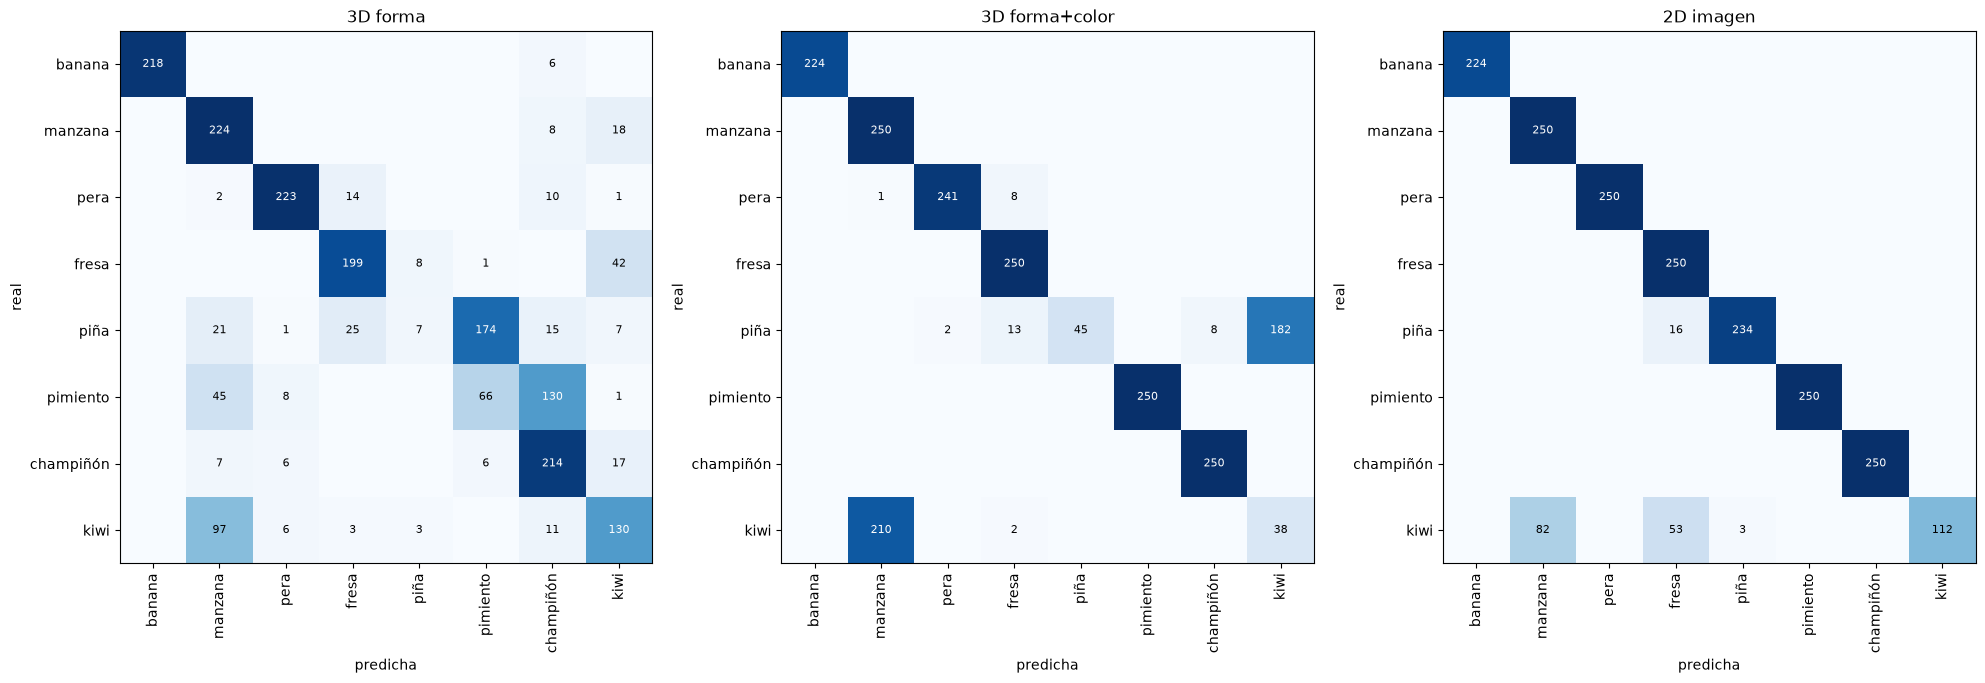

In [31]:
fig, ax = plt.subplots(1, 3, figsize=(20, 6.5))
for k, (nombre, p) in enumerate(modelos.items()):
    M = torch.zeros(len(CLASES), len(CLASES), dtype=torch.long)
    for r, q in zip(yte.cpu(), p.cpu()):
        M[r, q] += 1
    ax[k].imshow(M, cmap="Blues")
    for r in range(len(CLASES)):
        for q in range(len(CLASES)):
            if M[r, q]:
                ax[k].text(q, r, M[r, q].item(), ha="center", va="center", fontsize=8,
                           color="white" if M[r, q] > M.max() / 2 else "black")
    ax[k].set_xticks(range(len(CLASES)), CLASES, rotation=90); ax[k].set_yticks(range(len(CLASES)), CLASES)
    ax[k].set_title(nombre); ax[k].set_xlabel("predicha"); ax[k].set_ylabel("real")
plt.tight_layout()
plt.show()


**interprete los resultados obtenidos en la matriz de confusión**

Respuesta:...

**predicciones de la CNN 3D con color en 8 objetos de test**

en verde si acierta y en rojo si falla, con las 3 clases más probables

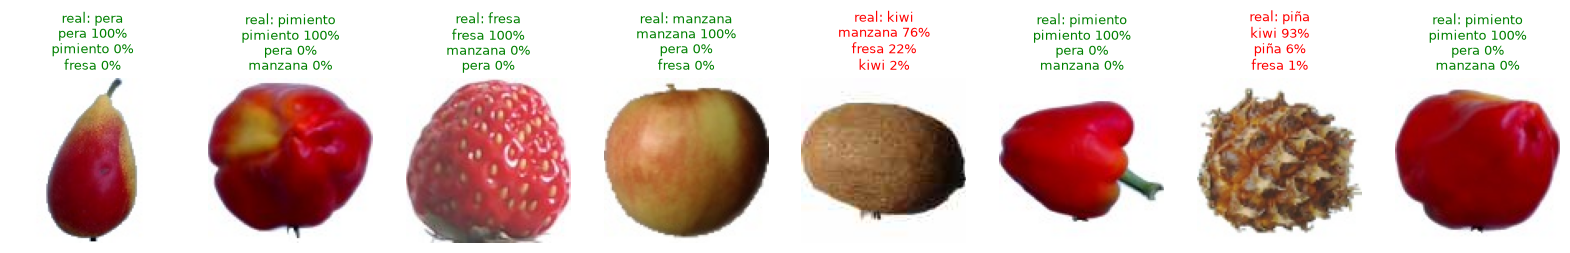

In [32]:
cnn_color.eval()
ejemplos = torch.randperm(len(Xte))[:8]
with torch.no_grad():
    prob = F.softmax(forma_color(Xte[ejemplos], Cte[ejemplos]), dim=1)

fig, ax = plt.subplots(1, 8, figsize=(20, 3.5))
for k, i in enumerate(ejemplos):
    top_p, top_c = prob[k].topk(3)
    acierto = top_c[0] == yte[i]
    ax[k].imshow(Image.open(arch_te[i])); ax[k].axis("off")
    ax[k].set_title(f"real: {CLASES[yte[i]]}\n" + "\n".join(f"{CLASES[c]} {v:.0%}" for v, c in zip(top_p, top_c)),
                    fontsize=9, color="green" if acierto else "red")
plt.show()

**8.- Probar con imágenes propias**

Para que una foto propia se parezca a las del dataset:
* la recortamos al objeto (todo lo que no es blanco)
* le agregamos un margen blanco y la dejamos cuadrada
* la achicamos a 100 × 100

funciona mejor con una sola fruta o verdura de estas 8 clases, centrada y sobre fondo blanco liso

In [33]:
def preparar(ruta, margen=0.05):
    img = np.array(Image.open(ruta).convert("RGB"))
    objeto = img.min(2) < 230
    filas, cols = np.where(objeto)
    img = img[filas.min():filas.max() + 1, cols.min():cols.max() + 1]   # recorta al objeto
    lado = int(max(img.shape[:2]) * (1 + 2 * margen))
    lienzo = np.full((lado, lado, 3), 255, dtype=np.uint8) # cuadrado blanco
    f0, c0 = (lado - img.shape[0]) // 2, (lado - img.shape[1]) // 2
    lienzo[f0:f0 + img.shape[0], c0:c0 + img.shape[1]] = img
    img = np.array(Image.fromarray(lienzo).resize((ANCHO, ALTO), Image.BICUBIC))
    return torch.tensor(img, device=DISP).permute(2, 0, 1).float() / 255

esta función hace todo el recorrido para una foto: preparar, profundidad, nube, voxelizar y clasificar con las dos redes 3D y con la 2D

muestra la foto, el mapa de profundidad y las 3 clases más probables de cada red, y devuelve la figura de la nube

In [34]:
def clasificar(ruta):
    ell = preparar(ruta)
    d = profundidad(ell[None])[0]
    P, C = a_nube(ell, d)
    I = F.interpolate(ell[None], size=(64, 64), mode="area")

    #define en los elementos de la lista los diferentes cnn entrenados
    for red in [cnn_forma, cnn_color, cnn_2d]:
        red.eval()

    with torch.no_grad():
        probs = {"3D forma": solo_forma(P[None], C[None]),
                 "3D forma+color": forma_color(P[None], C[None]),
                 "2D imagen": imagen_2d(I)}

    fig, ax = plt.subplots(1, 2 + len(probs), figsize=(14, 3))
    ax[0].imshow(ell.permute(1, 2, 0).cpu()); ax[0].set_title("foto", fontsize=9)
    ax[1].imshow(d.cpu(), cmap="inferno"); ax[1].set_title("profundidad", fontsize=9)
    for k, (nombre, logits) in enumerate(probs.items()):
        top_p, top_c = F.softmax(logits, dim=1)[0].topk(3)
        ax[k + 2].text(0, 0.5, nombre + "\n\n" + "\n".join(f"{CLASES[c]} {v:.0%}" for v, c in zip(top_p, top_c)),
                       va="center", fontsize=10)
    for x in ax: x.axis("off")
    plt.show()

    m = mascara(ell)
    fig = go.Figure(nube(ell, a_metros(d, m), m))
    fig.update_layout(scene=dict(aspectmode="data"), height=400, margin=dict(l=0, r=0, t=0, b=0))
    return fig

primero lo probamos con una foto de test del dataset

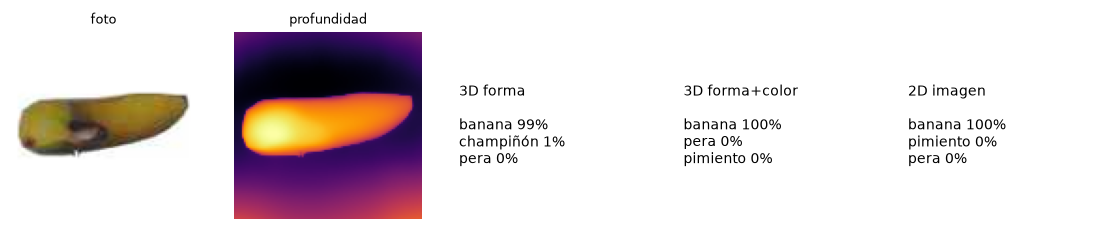

In [35]:
clasificar(arch_te[0]).show()

ahora con fotos propias: al ejecutar la celda aparece un botón para subir una o varias imágenes

deberias tener resultados como el siguiente: https://drive.google.com/file/d/11laAy1KRXc2plFrt_AalIrHIwlWvzVwl/view?usp=sharing

image\banana.jpg


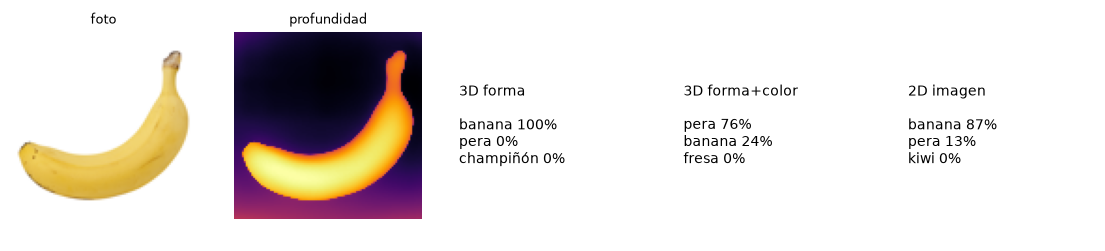

image\kiwi.jpg


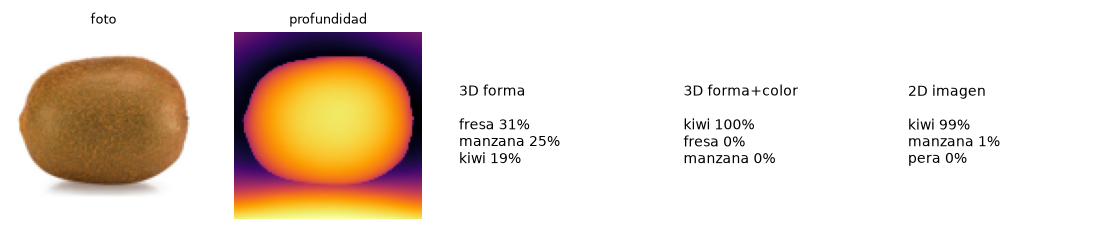

image\manzana.jpg


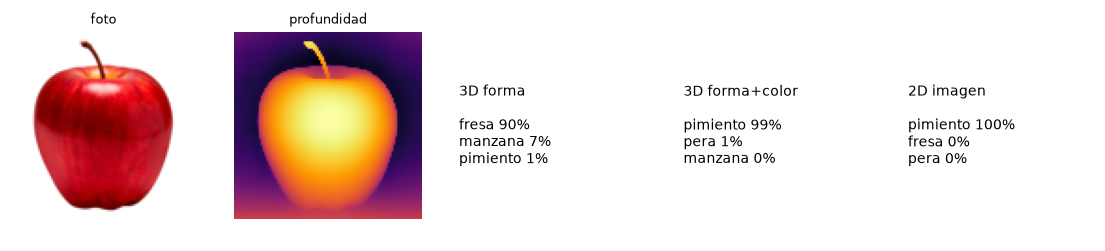

image\pera-2.jpg


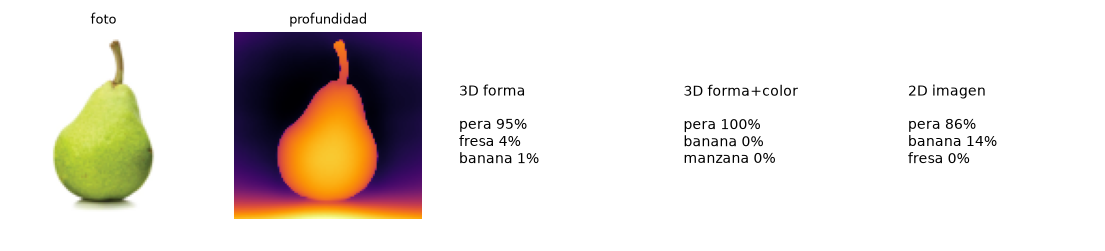

image\pera.jpg


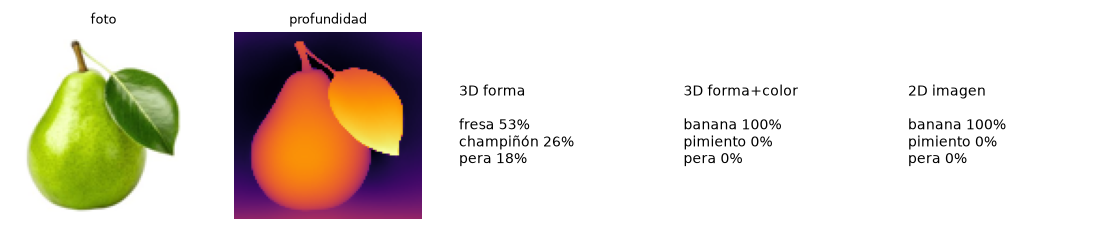

In [36]:
try:
    from google.colab import files
    subidas = files.upload()
except ImportError:
    subidas = sorted(glob.glob("image/*"))

for nombre in subidas:
    print(nombre)
    clasificar(nombre).show()


## **Ejercicio**
**1.- Entrene la CNN 3D con forma y color con 5, 15 y 30 épocas y anote la accuracy de test de cada una ¿sigue mejorando o se estanca?**

In [37]:
cnn_5 = crear_cnn(4)

def forma_color_5(P, C, aum=False):
    if aum:
        P, C = aumentar_puntos(P), aumentar_color(C)
    return cnn_5(voxelizar(P, 32, C))

pred_5 = entrenar(forma_color_5, cnn_5, (Xtr, Ctr, ytr), (Xte, Cte, yte), epocas=5)

época  1 | accuracy test 0.678
época  2 | accuracy test 0.734
época  3 | accuracy test 0.725
época  4 | accuracy test 0.770
época  5 | accuracy test 0.668
4.1 s por época


In [38]:
cnn_15 = crear_cnn(4)

def forma_color_15(P, C, aum=False):
    if aum:
        P, C = aumentar_puntos(P), aumentar_color(C)
    return cnn_15(voxelizar(P, 32, C))

pred_15 = entrenar(forma_color_15, cnn_15, (Xtr, Ctr, ytr), (Xte, Cte, yte), epocas=15)

época  1 | accuracy test 0.527
época  2 | accuracy test 0.733
época  3 | accuracy test 0.744
época  4 | accuracy test 0.673
época  5 | accuracy test 0.742
época  6 | accuracy test 0.750
época  7 | accuracy test 0.720
época  8 | accuracy test 0.766
época  9 | accuracy test 0.749
época 10 | accuracy test 0.744
época 11 | accuracy test 0.854
época 12 | accuracy test 0.852
época 13 | accuracy test 0.736
época 14 | accuracy test 0.756
época 15 | accuracy test 0.799
4.1 s por época


In [39]:
for ep, p in [(5, pred_5), (15, pred_15), (30, pred_color)]:
    print(f"{ep:2d} épocas: accuracy test {p.eq(yte).float().mean():.3f}")

 5 épocas: accuracy test 0.668
15 épocas: accuracy test 0.799
30 épocas: accuracy test 0.784


**2.- En a_nube cambie N=1024 por N=256 y reentrene ¿qué pasa con la accuracy con menos puntos por objeto?**

In [40]:
def procesar_256(archivos, lote=32):
    X, C, I = [], [], []
    for k in range(0, len(archivos), lote):
        ell = cargar(archivos[k:k + lote])
        d = profundidad(ell)
        I.append(F.interpolate(ell, size=(64, 64), mode="area"))
        for e, dd in zip(ell, d):
            p, c = a_nube(e, dd, N=256)
            X.append(p); C.append(c)
    return torch.stack(X), torch.stack(C), torch.cat(I)

In [41]:
Xtr256, Ctr256, _ = procesar_256(arch_tr, lote=16)
Xte256, Cte256, _ = procesar_256(arch_te, lote=16)

cnn_256 = crear_cnn(4)

def forma_color_256(P, C, aum=False):
    if aum:
        P, C = aumentar_puntos(P), aumentar_color(C)
    return cnn_256(voxelizar(P, 32, C))

pred_256 = entrenar(forma_color_256, cnn_256, (Xtr256, Ctr256, ytr), (Xte256, Cte256, yte), epocas=30)

época  1 | accuracy test 0.665
época  2 | accuracy test 0.649
época  3 | accuracy test 0.734
época  4 | accuracy test 0.736
época  5 | accuracy test 0.742
época  6 | accuracy test 0.751
época  7 | accuracy test 0.738
época  8 | accuracy test 0.777
época  9 | accuracy test 0.741
época 10 | accuracy test 0.734
época 11 | accuracy test 0.757
época 12 | accuracy test 0.757
época 13 | accuracy test 0.726
época 14 | accuracy test 0.757
época 15 | accuracy test 0.790
época 16 | accuracy test 0.850
época 17 | accuracy test 0.814
época 18 | accuracy test 0.861
época 19 | accuracy test 0.807
época 20 | accuracy test 0.768
época 21 | accuracy test 0.799
época 22 | accuracy test 0.787
época 23 | accuracy test 0.824
época 24 | accuracy test 0.884
época 25 | accuracy test 0.840
época 26 | accuracy test 0.837
época 27 | accuracy test 0.801
época 28 | accuracy test 0.847
época 29 | accuracy test 0.773
época 30 | accuracy test 0.834
6.5 s por época


**3.- Entrene la CNN 3D con forma y color pasando siempre aum=False, es decir, sin deformar puntos ni cambiar colores. Compare con el resultado original ¿el aumento de datos ayuda a reconocer la variedad de test?**

In [42]:
cnn_sin_aum = crear_cnn(4)

def forma_color_sin_aum(P, C, aum=False):
    return cnn_sin_aum(voxelizar(P, 32, C))

pred_sin_aum = entrenar(forma_color_sin_aum, cnn_sin_aum, (Xtr, Ctr, ytr), (Xte, Cte, yte), epocas=30)


época  1 | accuracy test 0.697
época  2 | accuracy test 0.741
época  3 | accuracy test 0.745
época  4 | accuracy test 0.745
época  5 | accuracy test 0.735
época  6 | accuracy test 0.727
época  7 | accuracy test 0.738
época  8 | accuracy test 0.739
época  9 | accuracy test 0.728
época 10 | accuracy test 0.743
época 11 | accuracy test 0.741
época 12 | accuracy test 0.745
época 13 | accuracy test 0.744
época 14 | accuracy test 0.741
época 15 | accuracy test 0.726
época 16 | accuracy test 0.733
época 17 | accuracy test 0.735
época 18 | accuracy test 0.740
época 19 | accuracy test 0.734
época 20 | accuracy test 0.733
época 21 | accuracy test 0.735
época 22 | accuracy test 0.732
época 23 | accuracy test 0.743
época 24 | accuracy test 0.737
época 25 | accuracy test 0.735
época 26 | accuracy test 0.730
época 27 | accuracy test 0.732
época 28 | accuracy test 0.740
época 29 | accuracy test 0.740
época 30 | accuracy test 0.733
6.5 s por época
